# Image Object and Face Detection using YOLO & OpenCV

## Overview

This notebook explores image-based object detection and face detection using pretrained YOLO models, the Ultralytics framework, and OpenCV.

The project uses two separate detection models:

- **YOLOv8n:** For general object detection.
- **YOLOv8m-face:** For human face detection.

Both models process the same input image independently. Their predictions are visualized individually and then combined into a single annotated image.

This experiment provides practical experience with pretrained computer vision models, image processing, object localization, and detection result analysis.

## Objectives

- Understand image-based object detection.
- Load and use pretrained YOLO models.
- Perform general object detection.
- Perform dedicated face detection.
- Combine predictions from multiple detection models.
- Understand bounding boxes and confidence scores.
- Visualize detection results using OpenCV and Matplotlib.
- Save the generated detection output.

## Workflow

1. Import required libraries.
2. Load pretrained YOLO models.
3. Configure detection parameters.
4. Load and visualize an input image.
5. Perform general object detection.
6. Perform face detection.
7. Combine both detection outputs.
8. Analyze detection results.
9. Save the final annotated image.
10. Document observations and conclusions.

## 1. Import Required Libraries

In this section, we import the Python libraries required for image processing, object detection, and visualization.

### Libraries Used

- **OpenCV (`cv2`):** Used for loading, processing, and saving images.
- **Matplotlib:** Used for displaying original and annotated images.
- **Pathlib:** Used for handling file and directory paths.
- **Ultralytics YOLO:** Used for loading pretrained YOLO models and performing inference.

In [20]:
# Image processing
import cv2

# Visualization
import matplotlib.pyplot as plt

# File and directory management
from pathlib import Path

# YOLO model
from ultralytics import YOLO

## 2. Load Pretrained Models

In this experiment, we use two independent pretrained YOLO models for different detection tasks.

### Model 1: YOLOv8n

- Model: `yolov8n.pt`
- Purpose: General object detection.
- Architecture: YOLOv8 Nano.

### Model 2: YOLOv8m-face

- Model: `yolov8m-face.pt`
- Purpose: Human face detection.
- Source: [YOLO Face Repository](https://github.com/akanametov/yolo-face)

The models are loaded separately so that their predictions can be generated and analyzed independently.

**Note:** These are pretrained models. No model training or fine-tuning is performed in this experiment.

In [21]:
# Define project directory
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "models").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "models").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError("Project root or models directory not found.")

# Define model paths
OBJECT_MODEL_PATH = PROJECT_ROOT / "models" / "yolov8n.pt"
FACE_MODEL_PATH = PROJECT_ROOT / "models" / "yolov8m-face.pt"

# Verify model files
if not OBJECT_MODEL_PATH.exists():
    raise FileNotFoundError(f"Object model not found: {OBJECT_MODEL_PATH}")

if not FACE_MODEL_PATH.exists():
    raise FileNotFoundError(f"Face model not found: {FACE_MODEL_PATH}")

# Load pretrained models
object_model = YOLO(str(OBJECT_MODEL_PATH))
face_model = YOLO(str(FACE_MODEL_PATH))

print("Both YOLO models loaded successfully!")

Both YOLO models loaded successfully!


## 3. Detection Configuration

In this section, we define the configuration parameters used during model inference.

### Confidence Threshold

The confidence threshold determines the minimum confidence score required for a detection to be retained.

- A higher threshold generally filters out more low-confidence predictions.
- A lower threshold may allow more predictions, including uncertain detections.

We start with a confidence threshold of `0.40` for both models.

This value can be adjusted during future experiments to study its effect on detection results.

In [22]:
# Detection configuration

CONFIDENCE_THRESHOLD = 0.40

print("Detection Configuration")
print("-" * 30)
print("Confidence Threshold:", CONFIDENCE_THRESHOLD)

Detection Configuration
------------------------------
Confidence Threshold: 0.4


## 4. Load Input Image

We will use an example image stored inside the `assets/demo-images/` directory.

OpenCV's `imread()` function loads an image in BGR (Blue, Green, Red) color format.

Before performing detection, we verify that the image has been loaded successfully.

We also inspect the image dimensions to understand its resolution.

In [23]:
# Define input image path
IMAGE_PATH = PROJECT_ROOT / "assets" / "demo-images" / "demo2.jpg"

# Load image using OpenCV
photo = cv2.imread(str(IMAGE_PATH))

# Verify image loading
if photo is None:
    raise FileNotFoundError(f"Unable to load image: {IMAGE_PATH}")

# Display image information
print("Image loaded successfully!")
print("Image shape:", photo.shape)
print("Image height:", photo.shape[0])
print("Image width:", photo.shape[1])
print("Number of channels:", photo.shape[2])

Image loaded successfully!
Image shape: (624, 936, 3)
Image height: 624
Image width: 936
Number of channels: 3


## 5. Visualize Original Image

Before applying the detection models, we visualize the original input image.

OpenCV loads images in BGR format, whereas Matplotlib expects RGB format for correct color visualization.

Therefore, we convert the image from BGR to RGB before displaying it.

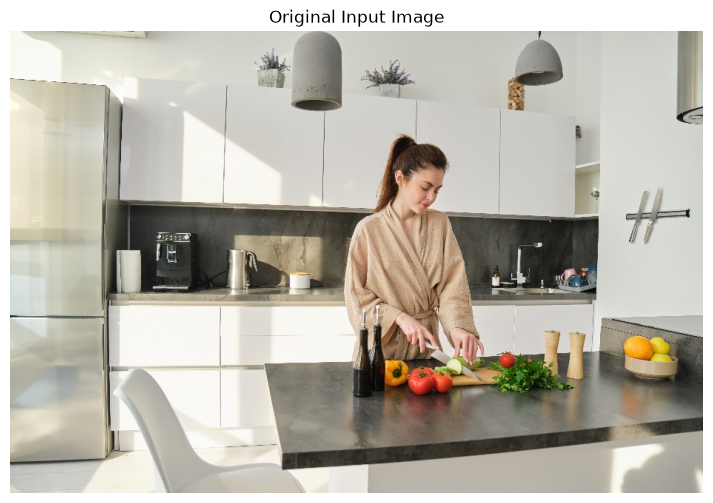

In [24]:
# Convert BGR image to RGB
original_rgb = cv2.cvtColor(photo, cv2.COLOR_BGR2RGB)

# Display original image
plt.figure(figsize=(10, 6))

plt.imshow(original_rgb)
plt.title("Original Input Image")
plt.axis("off")

plt.show()

## 6. General Object Detection

In this section, we perform general object detection using the pretrained YOLOv8 Nano model.

The model processes the input image and identifies objects belonging to its supported detection classes.

For each detected object, the model can provide:

- **Class ID:** Numeric identifier of the predicted object class.
- **Class Name:** Human-readable name of the predicted class.
- **Confidence Score:** Confidence associated with the prediction.
- **Bounding Box:** Coordinates representing the detected object's location.

The confidence threshold defined earlier is applied during inference.

The resulting predictions are visualized using the Ultralytics plotting functionality.

In [28]:
# Perform general object detection
object_results = object_model(
    photo,
    conf=CONFIDENCE_THRESHOLD
)

# Extract the first prediction result
object_result = object_results[0]

# Generate annotated image
object_detected = object_result.plot()

# Display detection information
print("General object detection completed!")
print("Objects detected:", len(object_result.boxes))
# display(object_result)



0: 448x640 1 person, 2 bottles, 2 apples, 1 orange, 1 chair, 1 potted plant, 1 refrigerator, 11.5ms
Speed: 2.8ms preprocess, 11.5ms inference, 1.5ms postprocess per image at shape (1, 3, 448, 640)
General object detection completed!
Objects detected: 9


### Visualizing General Object Detection

The following visualization displays the input image with bounding boxes, class labels, and confidence scores generated by the general object detection model.

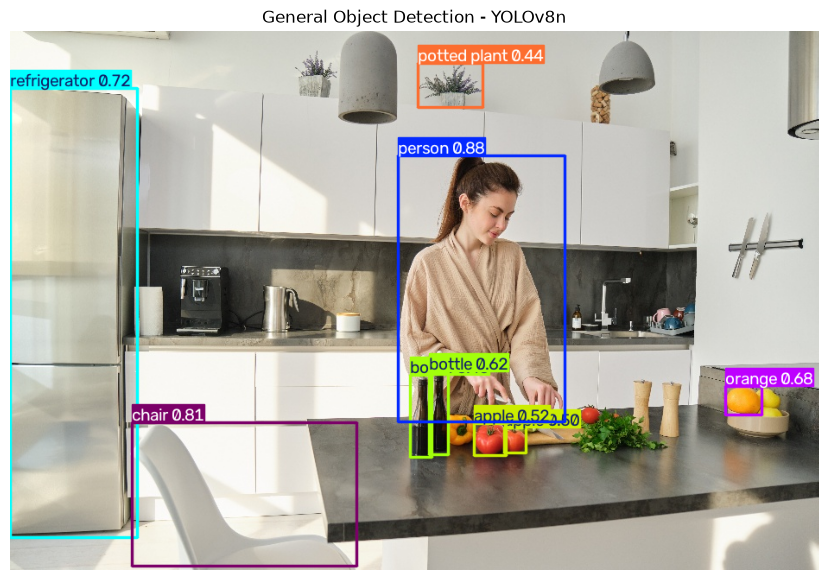

In [29]:
# Convert annotated image from BGR to RGB
object_rgb = cv2.cvtColor(
    object_detected,
    cv2.COLOR_BGR2RGB
)

# Display object detection result
plt.figure(figsize=(12, 7))

plt.imshow(object_rgb)
plt.title("General Object Detection - YOLOv8n")
plt.axis("off")

plt.show()

## 7. Face Detection

In this section, we perform face detection using a dedicated pretrained YOLO-based face detection model.

The model used is `yolov8m-face.pt`, obtained from the [YOLO Face repository](https://github.com/akanametov/yolo-face).

Unlike the general object detection model, this model is specifically designed to identify human faces.

The same input image is processed independently by the face detection model.

We apply the same confidence threshold and visualize the resulting face predictions.

In [31]:
# Perform face detection
face_results = face_model(
    photo,
    conf=CONFIDENCE_THRESHOLD
)

# Extract the first prediction result
face_result = face_results[0]

# Generate annotated image : Annotated images are pictures that have been marked, tagged, or labeled with extra information, shapes, or text to explain what is inside them
face_detected = face_result.plot()

# Display detection information

print("Face detection completed!")
print("Faces detected:", len(face_result.boxes))

0: 640x960 1 face, 100.1ms
Speed: 5.6ms preprocess, 100.1ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 960)
Face detection completed!
Faces detected: 1


### Visualizing Face Detection

The following visualization displays the detected faces with their bounding boxes and confidence scores.

The output helps us inspect how the dedicated face detection model performs on the selected image.

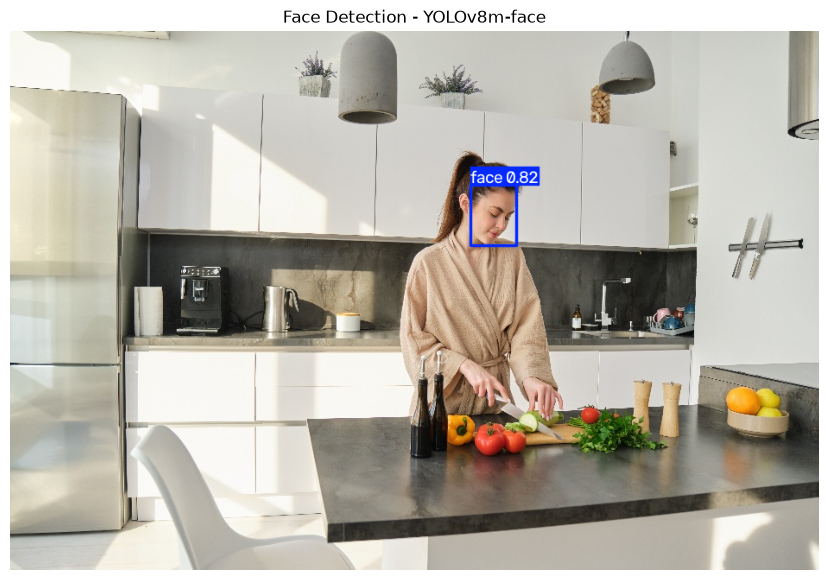

In [32]:
# Convert annotated image from BGR to RGB
face_rgb = cv2.cvtColor(
    face_detected,
    cv2.COLOR_BGR2RGB
)

# Display face detection result
plt.figure(figsize=(12, 7))

plt.imshow(face_rgb)
plt.title("Face Detection - YOLOv8m-face")
plt.axis("off")

plt.show()

## 8. Combined Object and Face Detection

In this experiment, we combine the visual predictions generated by both YOLO models.

The process involves two steps:

1. The general object detection model annotates the original image.
2. The face detection model adds its annotations to the already annotated image.

This produces a single visualization containing the predictions from both models.

**Important:** This process combines visual annotations only. The models remain independent, and their underlying predictions are not merged into a single unified detection model.

Overlapping bounding boxes may occur when both models identify the same image region.

In [33]:
# Generate object detection annotations
object_annotated = object_result.plot()

# Add face detection annotations
combined_result = face_result.plot(
    img=object_annotated
)

print("Combined detection completed successfully!")

Combined detection completed successfully!


### Visualizing Combined Detection Results

The following output shows the combined annotations from the general object detection and face detection models.

This visualization allows us to inspect the predictions from both models in one image.

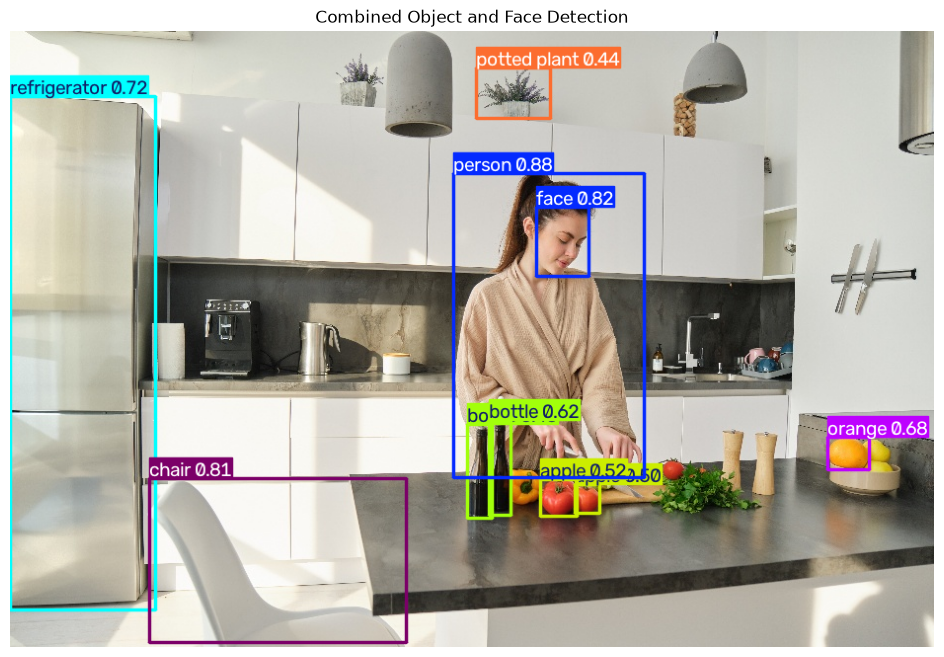

In [34]:
# Convert combined result from BGR to RGB
combined_rgb = cv2.cvtColor(
    combined_result,
    cv2.COLOR_BGR2RGB
)

# Display combined detection result
plt.figure(figsize=(14, 8))

plt.imshow(combined_rgb)
plt.title("Combined Object and Face Detection")
plt.axis("off")

plt.show()

## 9. Understanding Object Detection Results

Ultralytics YOLO returns a Results object containing information about the predictions generated by the model.

Each detected object can contain several important attributes.

### Important Prediction Attributes

- **`boxes`:** Contains the detected bounding boxes.
- **`cls`:** Contains the predicted class IDs.
- **`conf`:** Contains the confidence scores.
- **`xyxy`:** Contains bounding box coordinates in the format `(x1, y1, x2, y2)`.
- **`names`:** Maps class IDs to their corresponding class names.

We can access these attributes to inspect the model's predictions programmatically rather than relying only on visual output.

In [36]:
# Access object detection results
print("OBJECT DETECTION ANALYSIS")
print("=" * 50)

for index, box in enumerate(object_result.boxes, start=1):

    # Extract class ID
    class_id = int(box.cls[0])

    # Extract class name
    class_name = object_result.names[class_id]

    # Extract confidence score
    confidence = float(box.conf[0])

    # Extract bounding box coordinates
    x1, y1, x2, y2 = box.xyxy[0].tolist()

    print(f"\nDetection {index}")
    print(f"Class ID: {class_id}")
    print(f"Class Name: {class_name}")
    print(f"Confidence: {confidence:.2f}")

    print(
        f"Bounding Box: "
        f"({x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f})"
    )

    print("-" * 50)

OBJECT DETECTION ANALYSIS

Detection 1
Class ID: 0
Class Name: person
Confidence: 0.88
Bounding Box: (449.5, 144.5, 642.1, 452.5)
--------------------------------------------------

Detection 2
Class ID: 56
Class Name: chair
Confidence: 0.81
Bounding Box: (141.4, 453.6, 401.2, 619.6)
--------------------------------------------------

Detection 3
Class ID: 72
Class Name: refrigerator
Confidence: 0.72
Bounding Box: (0.0, 66.7, 147.2, 586.5)
--------------------------------------------------

Detection 4
Class ID: 49
Class Name: orange
Confidence: 0.68
Bounding Box: (828.6, 411.6, 870.2, 444.4)
--------------------------------------------------

Detection 5
Class ID: 39
Class Name: bottle
Confidence: 0.62
Bounding Box: (485.3, 394.8, 507.9, 490.6)
--------------------------------------------------

Detection 6
Class ID: 47
Class Name: apple
Confidence: 0.52
Bounding Box: (537.6, 454.2, 574.4, 491.6)
--------------------------------------------------

Detection 7
Class ID: 47
Class Name: 

## 10. Face Detection Analysis

In this section, we inspect the predictions generated by the dedicated face detection model.

For each detected face, we extract:

- Detection index.
- Confidence score.
- Bounding box coordinates.

Unlike the general object detection model, this model is focused on face detection.

We also calculate the total number of detected faces.

In [37]:
# Analyze face detection predictions
print("FACE DETECTION ANALYSIS")
print("=" * 50)

for index, box in enumerate(face_result.boxes, start=1):

    # Extract confidence score
    confidence = float(box.conf[0])

    # Extract bounding box coordinates
    x1, y1, x2, y2 = box.xyxy[0].tolist()

    print(f"\nFace {index}")
    print(f"Confidence: {confidence:.2f}")

    print(
        f"Bounding Box: "
        f"({x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f})"
    )

    print("-" * 50)

print("\nTotal Faces Detected:", len(face_result.boxes))

FACE DETECTION ANALYSIS

Face 1
Confidence: 0.82
Bounding Box: (533.7, 178.1, 586.7, 248.4)
--------------------------------------------------

Total Faces Detected: 1


## 11. Detection Summary

In this section, we summarize the predictions generated by both detection models.

The summary includes:

- General object detection model.
- Dedicated face detection model.
- Confidence threshold.
- Total object detections.
- Total face detections.

The detection counts are reported separately because the two models perform different prediction tasks and may identify overlapping regions.

In [38]:
# Calculate detection counts
object_count = len(object_result.boxes)
face_count = len(face_result.boxes)

# Display detection summary
print("=" * 50)
print("             DETECTION SUMMARY")
print("=" * 50)

print(f"Object Model       : YOLOv8n")
print(f"Face Model         : YOLOv8m-face")
print(f"Confidence Threshold: {CONFIDENCE_THRESHOLD:.2f}")

print("-" * 50)

print(f"Objects Detected   : {object_count}")
print(f"Faces Detected     : {face_count}")

print("=" * 50)

             DETECTION SUMMARY
Object Model       : YOLOv8n
Face Model         : YOLOv8m-face
Confidence Threshold: 0.40
--------------------------------------------------
Objects Detected   : 9
Faces Detected     : 1


## 12. Save Detection Results

After completing the detection experiments, we save the combined annotated image.

The output is stored inside the `assets/screenshots/` directory.

Saving the result allows us to reuse the generated visualization without running the detection models again.

We also verify whether the image was saved successfully.

In [39]:
# Define output directory
OUTPUT_DIR = PROJECT_ROOT / "assets" / "screenshots"

# Create output directory if it does not exist
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Define output image path
OUTPUT_PATH = OUTPUT_DIR / "combined-detection.png"

# Save combined detection image
success = cv2.imwrite(
    str(OUTPUT_PATH),
    combined_result
)

# Verify saving operation
if success:
    print("Detection output saved successfully!")
    print("Saved location:", OUTPUT_PATH)
else:
    raise IOError("Failed to save the detection output.")

Detection output saved successfully!
Saved location: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\assets\screenshots\combined-detection.png


## 13. Observations and Analysis

This section documents the observations obtained from the object detection, face detection, and combined detection experiments.

### 1. General Object Detection

Record the following observations:

- Which object classes were detected?
- How many objects were identified?
- What confidence scores were produced?
- Were any objects missed or incorrectly detected?

### 2. Face Detection

Record the following observations:

- How many faces were detected?
- Were all visible faces identified?
- How did the confidence scores vary?
- Were any faces missed?

### 3. Combined Detection

Observe the combined output:

- Were predictions from both models visible?
- Did any bounding boxes overlap?
- Were the annotations readable?
- Did combining the visual predictions improve the overall visualization?

### 4. Overall Analysis

Compare the general object detection model with the dedicated face detection model.

Document the differences in their predictions, detection capabilities, and limitations based on the actual experiment.

## 14. Key Learnings

Through this experiment, I explored the following computer vision concepts:

- Loading pretrained YOLO models using the Ultralytics framework.
- Performing image-based object detection.
- Using a dedicated model for face detection.
- Understanding bounding boxes and object localization.
- Extracting class IDs, class names, and confidence scores.
- Processing images using OpenCV.
- Visualizing detection predictions using Matplotlib.
- Combining annotations from multiple independent detection models.
- Saving generated detection results.

This experiment provided practical experience with pretrained computer vision models and image inference workflows.

## 15. Conclusion

In this experiment, an image-based object and face detection system was implemented using two independent pretrained YOLO models.

The Ultralytics framework was used to perform inference, while OpenCV and Matplotlib supported image processing and visualization.

The general object detection model identified supported object classes, while the dedicated face detection model identified human faces.

The predictions from both models were visually combined to generate a single annotated image.

This experiment provided practical experience with pretrained computer vision models, image inference, bounding box analysis, and detection visualization.

### Future Scope

The project can be extended through:

- Video-based object and face detection.
- Real-time webcam detection.
- Confidence threshold experimentation.
- Model performance comparison.
- Reusable Python detection modules.
- Interactive web application development.

## 16. References

The following documentation and repositories were used as references during this experiment.

1. [Ultralytics Documentation](https://docs.ultralytics.com/)
2. [Ultralytics GitHub Repository](https://github.com/ultralytics/ultralytics)
3. [YOLO Face Repository](https://github.com/akanametov/yolo-face)
4. [OpenCV Documentation](https://docs.opencv.org/)
5. [Matplotlib Documentation](https://matplotlib.org/stable/)

These resources provide information about YOLO models, computer vision operations, image processing, and visualization.